# Week 2 – Sales Data Analysis Using Python
This notebook uses Pandas, NumPy and Matplotlib to clean and analyze the provided sample sales dataset.

**Before running:** upload `sales_data.csv` to the same Colab session using the Files panel.

# New Section

In [1]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(42)

n = 500
products = ["Laptop", "Smartphone", "Headphones", "Smartwatch",
            "Tablet", "Keyboard", "Mouse"]

prices = {
    "Laptop": 55000,
    "Smartphone": 22000,
    "Headphones": 1800,
    "Smartwatch": 6500,
    "Tablet": 18000,
    "Keyboard": 900,
    "Mouse": 500
}

cities = ["Bengaluru", "Kalaburagi", "Hyderabad",
          "Pune", "Mumbai", "Chennai", "Delhi"]

categories = {
    "Laptop": "Electronics",
    "Smartphone": "Electronics",
    "Headphones": "Accessories",
    "Smartwatch": "Wearables",
    "Tablet": "Electronics",
    "Keyboard": "Accessories",
    "Mouse": "Accessories"
}

product = rng.choice(products, n)
quantity = rng.integers(1, 6, n)

df = pd.DataFrame({
    "Order_ID": [f"ORD{i:04d}" for i in range(1, n+1)],
    "Order_Date": rng.choice(
        pd.date_range("2025-01-01", "2025-12-31"), n),
    "Product": product,
    "Category": [categories[p] for p in product],
    "Quantity": quantity,
    "Unit_Price": [prices[p] for p in product],
    "City": rng.choice(cities, n)
})

df["Sales"] = df["Quantity"] * df["Unit_Price"]

df.to_csv("sales_data.csv", index=False)

print("Sales dataset created successfully!")
print(df.head())
print("Total records:", len(df))

Sales dataset created successfully!
  Order_ID Order_Date     Product     Category  Quantity  Unit_Price  \
0  ORD0001 2025-10-23      Laptop  Electronics         1       55000   
1  ORD0002 2025-09-26    Keyboard  Accessories         4         900   
2  ORD0003 2025-07-23      Tablet  Electronics         5       18000   
3  ORD0004 2025-11-20  Smartwatch    Wearables         5        6500   
4  ORD0005 2025-02-16  Smartwatch    Wearables         2        6500   

         City  Sales  
0        Pune  55000  
1  Kalaburagi   3600  
2  Kalaburagi  90000  
3   Hyderabad  32500  
4      Mumbai  13000  
Total records: 500


In [2]:
%pip -q install pandas numpy matplotlib

## Load, clean, analyze and visualize the sales data

Original dataset shape: (500, 8)


,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,City,Sales
0,ORD0001,2025-10-23,Laptop,Electronics,1,55000,Pune,55000
1,ORD0002,2025-09-26,Keyboard,Accessories,4,900,Kalaburagi,3600
2,ORD0003,2025-07-23,Tablet,Electronics,5,18000,Kalaburagi,90000
3,ORD0004,2025-11-20,Smartwatch,Wearables,5,6500,Hyderabad,32500
4,ORD0005,2025-02-16,Smartwatch,Wearables,2,6500,Mumbai,13000



Missing values before cleaning:
Order_ID      0
Order_Date    0
Product       0
Category      0
Quantity      0
Unit_Price    0
City          0
Sales         0
dtype: int64

Missing values after cleaning:
Order_ID      0
Order_Date    0
Product       0
Category      0
Quantity      0
Unit_Price    0
City          0
Sales         0
dtype: int64

Cleaned dataset shape: (500, 8)


,Sales
Month,
2025-01,1708300
2025-02,1452600
2025-03,1201600
2025-04,1532200
2025-05,1845400
2025-06,1657000
2025-07,2870600
2025-08,1765200
2025-09,2087800


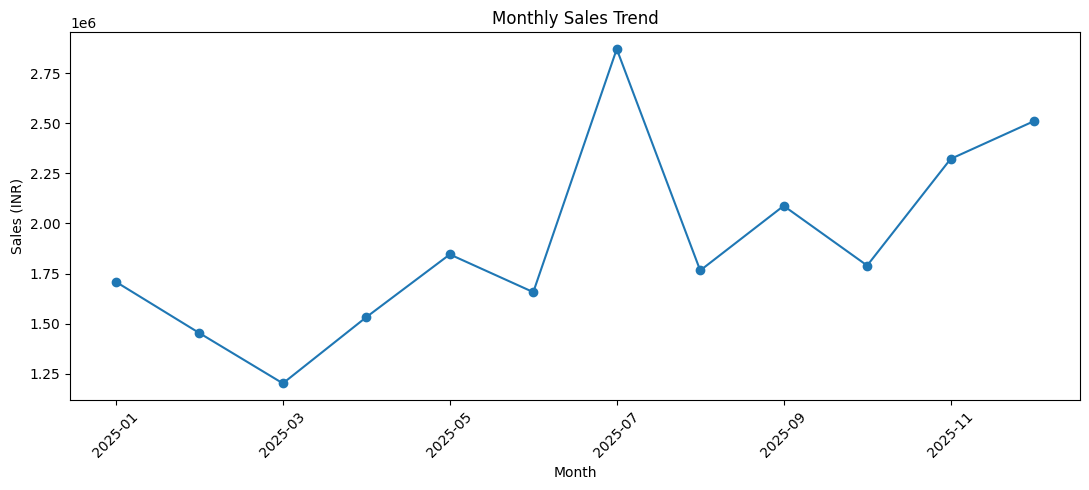

,Quantity
Product,
Smartwatch,274
Keyboard,248
Laptop,234
Headphones,206
Tablet,189
Mouse,185
Smartphone,182


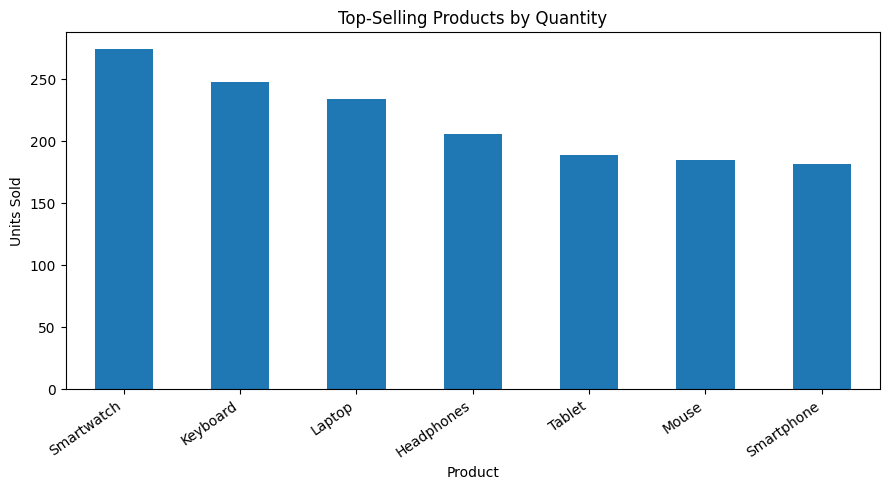

,Sales
City,
Chennai,4095000
Mumbai,3795500
Pune,3338200
Delhi,3230600
Bengaluru,2997400
Kalaburagi,2913000
Hyderabad,2373800


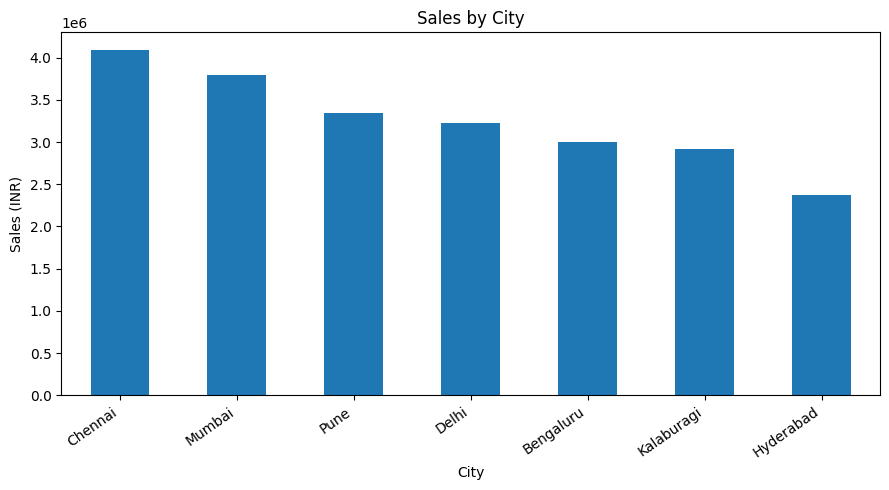


========== BUSINESS SUMMARY ==========
Total revenue: ₹22,743,500.00
Total orders: 500
Best-selling product (quantity): Smartwatch
Highest-sales city: Chennai
Best month by revenue: 2025-07

Cleaned dataset and summary CSV files exported.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load dataset
df = pd.read_csv("sales_data.csv")
print("Original dataset shape:", df.shape)
display(df.head())
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# 2. Clean data
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce")
df["City"] = df["City"].fillna("Unknown")
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
df["Unit_Price"] = df["Unit_Price"].fillna(df["Unit_Price"].median())
df = df.dropna(subset=["Order_Date", "Product"]).drop_duplicates()
df["Sales"] = df["Quantity"] * df["Unit_Price"]

print("\nMissing values after cleaning:")
print(df.isnull().sum())
print("\nCleaned dataset shape:", df.shape)

# 3. Monthly sales
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)
monthly_sales = df.groupby("Month")["Sales"].sum().sort_index()
display(monthly_sales)

plt.figure(figsize=(11, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Top-selling products by quantity
product_quantity = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)
display(product_quantity)

plt.figure(figsize=(9, 5))
product_quantity.plot(kind="bar")
plt.title("Top-Selling Products by Quantity")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# 5. Sales by city
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False)
display(city_sales)

plt.figure(figsize=(9, 5))
city_sales.plot(kind="bar")
plt.title("Sales by City")
plt.xlabel("City")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# 6. Business summary
print("\n========== BUSINESS SUMMARY ==========")
print(f"Total revenue: ₹{df['Sales'].sum():,.2f}")
print(f"Total orders: {df['Order_ID'].nunique()}")
print(f"Best-selling product (quantity): {product_quantity.index[0]}")
print(f"Highest-sales city: {city_sales.index[0]}")
print(f"Best month by revenue: {monthly_sales.idxmax()}")
print("======================================")

# 7. Export cleaned dataset and summaries
df.to_csv("cleaned_sales_data.csv", index=False)
monthly_sales.to_csv("monthly_sales_summary.csv", header=["Sales"])
product_quantity.to_csv("product_sales_summary.csv", header=["Quantity_Sold"])
city_sales.to_csv("city_sales_summary.csv", header=["Sales"])
print("\nCleaned dataset and summary CSV files exported.")
